# Forecast-period land ensemble model evaluation

Reads selected ensemble fields and references only when their diagnostic cache is missing or forced, computes extended verification metrics, then plots selected cached maps.


## 1. Libraries


In [1]:
from pathlib import Path
import sys
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt


## 2. User setup


In [2]:
from pathlib import Path
INPUT_DATA_ROOT = Path("/compyfs/zhan391/v3_dart_cda_scratch")
OBSERVATION_ROOT = Path("/compyfs/zhan391/acme_init/Observations")   # observations (shared archive)
WORK_DIR = Path("/compyfs/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/compyfs/www/zhan391/e3sm_dart/diag_dart_2026")

workflow_name = "fcst_lnd_model_evaluation"
component = "lnd"
run_segment = "fc"
season = "S0"
experiments = ("CTRL10-S0", "REAN10-S0", "CAPT10-S0", "DART20-S0", "DART40-S0")
variables = ("TSA", "H2OSOI", "SOILWATER_10CM")
plot_metrics = ("bias", "rmse", "spread", "crps")
lat_range = (-90, 90)
lon_range = (-180, 180)
max_members = None
n_bootstrap = 0
include_rank_histogram = True
random_seed = 42
force_compute = False
show = True

FIGURE_DPI = 200


## Notes: available variables and metrics

Atmosphere variables: `FLUT` (CERES-OAFlux), `PRECT` (GPCP), `TMQ`, `TS`, `TREFHT`, and `PSL` (ERA5). Land variables: `TSA` (MODIS LST), `H2OSOI` top 5 cm (ESA CCI), and `SOILWATER_10CM` (CPC soil moisture).

Map metrics: `mean`, `reference_mean`, `bias`, `bias_stddev`, `rmse`, `spread`, `crps`, and `coverage`. Scalar metrics: `model_global_mean`, `reference_global_mean`, `model_rms`, `reference_rms`, `rmse_global`, `pattern_correlation`, `bias_global`, `spread_global`, `crps_global`, `coverage_global`, `ssr`, `bias_squared`, `spread_squared`, `mse`, and `sem`. Optional: `rank_histogram`. With `n_bootstrap > 0`, bias/RMSE/spread/CRPS confidence bounds are cached too.

Existing request-keyed NetCDF files are reused. Set `force_compute = True` to reread raw model/reference data and rebuild them.


## 3. Project setup


In [3]:
import sys
import pandas as pd
import xarray as xr
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.bias_metrics import ATM_VARIABLES, LND_VARIABLES, experiment_registry, read_model_ensemble, read_reference
from util.model_evaluation import MAP_METRICS, SCALAR_METRICS, OPTIONAL_METRICS, evaluation_cache_path, cache_evaluation, plot_evaluation_maps


/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 4. Read, process, and cache


In [4]:
component_variables = ATM_VARIABLES if component == "atm" else LND_VARIABLES
data_dir, figure_dir = workflow_output_dirs(
    workflow_name, output_root=DIAGNOSTIC_OUTPUT_ROOT
)
registry = experiment_registry(INPUT_DATA_ROOT, season, run_segment)
unknown = set(experiments) - set(registry)
if unknown:
    raise ValueError(
        f"Unavailable experiments: {sorted(unknown)}; choose from {list(registry)}"
    )

all_results = {}
for variable in variables:
    if variable not in component_variables:
        raise ValueError(
            f"{variable} unavailable for {component}; "
            f"choose from {list(component_variables)}"
        )
    variable_results = {}
    for experiment in experiments:
        period = registry[experiment]["period"]
        target = evaluation_cache_path(data_dir, experiment, variable, period)
        if target.is_file() and not force_compute:
            ds = cache_evaluation(target, n_bootstrap=n_bootstrap)
            print(f"[REUSE] {target}")
        else:
            model, meta = read_model_ensemble(
                INPUT_DATA_ROOT, experiment, season, run_segment, component,
                variable, period=period, lat_range=lat_range,
                lon_range=lon_range, max_members=max_members,
            )
            reference = read_reference(
                OBSERVATION_ROOT, component, variable, period,
                lat_range=lat_range, lon_range=lon_range,
            )
            ds = cache_evaluation(
                target, model=model, reference=reference,
                force_compute=force_compute, experiment=experiment,
                variable=variable, component=component,
                run_segment=run_segment, season=season, period=period,
                n_bootstrap=n_bootstrap, random_seed=random_seed,
                include_rank_histogram=include_rank_histogram,
            )
            print(f"[WRITE] {target}")
        variable_results[experiment] = ds
    all_results[variable] = variable_results


/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


[WRITE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/fcst_lnd_model_evaluation/CTRL10-S0_TSA_201201-201202_model_evaluation.nc


/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


[WRITE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/fcst_lnd_model_evaluation/REAN10-S0_TSA_201201-201202_model_evaluation.nc


/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


[WRITE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/fcst_lnd_model_evaluation/CAPT10-S0_TSA_201201-201202_model_evaluation.nc


... (28 outputs left out)

[WRITE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/fcst_lnd_model_evaluation/DART20-S0_SOILWATER_10CM_201201-201202_model_evaluation.nc


/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


[WRITE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/data/fcst_lnd_model_evaluation/DART40-S0_SOILWATER_10CM_201201-201202_model_evaluation.nc


/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/qfs/people/zhan391/.conda/envs/e3sm_analysis/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2053: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


## 5. Plot, save, and show


[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_lnd_model_evaluation/TSA_bias_S0_fc.png


[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_lnd_model_evaluation/TSA_rmse_S0_fc.png


[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_lnd_model_evaluation/TSA_spread_S0_fc.png


[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_lnd_model_evaluation/TSA_crps_S0_fc.png


[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_lnd_model_evaluation/H2OSOI_bias_S0_fc.png


[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_lnd_model_evaluation/H2OSOI_rmse_S0_fc.png


... (3 outputs left out)

[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_lnd_model_evaluation/SOILWATER_10CM_rmse_S0_fc.png


[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_lnd_model_evaluation/SOILWATER_10CM_spread_S0_fc.png


[FIGURE] /compyfs/www/zhan391/e3sm_dart/diag_dart_2026/figure/fcst_lnd_model_evaluation/SOILWATER_10CM_crps_S0_fc.png


,variable,experiment,model_global_mean,reference_global_mean,model_rms,reference_rms,rmse_global,pattern_correlation,bias_global,spread_global,crps_global,coverage_global,ssr,bias_squared,spread_squared,mse,sem
0,TSA,CTRL10-S0,5.084672,2.286469,18.876331,23.022356,6.120528,0.978738,1.894271,1.145394,4.130080,0.081963,0.187140,3.588261,1.311927,37.460865,0.362205
1,TSA,REAN10-S0,3.164218,2.286469,18.165869,23.022356,6.832320,0.970875,-0.088737,1.047308,5.416889,0.052720,0.153287,0.007874,1.096855,46.680595,0.331188
2,TSA,CAPT10-S0,5.393502,2.286469,18.669766,23.022356,6.430466,0.977780,2.248666,1.030836,4.443371,0.068770,0.160305,5.056498,1.062622,41.350896,0.325979
3,TSA,DART20-S0,5.150256,2.286469,18.686826,23.022356,6.348832,0.977456,1.970032,1.310701,4.194845,0.101571,0.206448,3.881025,1.717937,40.307665,0.293082
4,TSA,DART40-S0,5.123865,2.286469,18.756339,23.022356,6.255849,0.978053,1.944012,1.349334,4.088191,0.117031,0.215692,3.779181,1.820702,39.135650,0.213348
5,H2OSOI,CTRL10-S0,0.241495,0.192782,0.170505,0.089718,0.053725,0.864815,-0.004540,0.012429,0.038339,0.040981,0.231354,0.000021,0.000154,0.002886,0.003931
6,H2OSOI,REAN10-S0,0.240776,0.192782,0.170511,0.089718,0.059745,0.834062,-0.006803,0.011344,0.042745,0.034641,0.189868,0.000046,0.000129,0.003569,0.003587
7,H2OSOI,CAPT10-S0,0.240227,0.192782,0.171604,0.089718,0.055251,0.865030,-0.009493,0.011126,0.038925,0.034939,0.201371,0.000090,0.000124,0.003053,0.003518
8,H2OSOI,DART20-S0,0.238939,0.192782,0.169971,0.089718,0.051974,0.874487,-0.008233,0.013915,0.036134,0.049763,0.267737,0.000068,0.000194,0.002701,0.003112
9,H2OSOI,DART40-S0,0.238865,0.192782,0.169778,0.089718,0.051643,0.873860,-0.008829,0.014517,0.035354,0.059162,0.281099,0.000078,0.000211,0.002667,0.002295


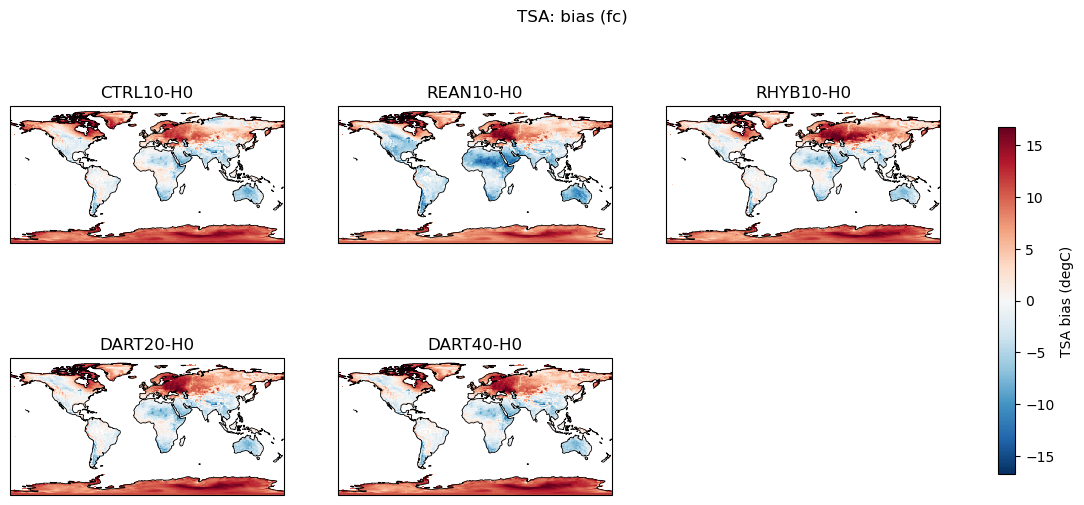

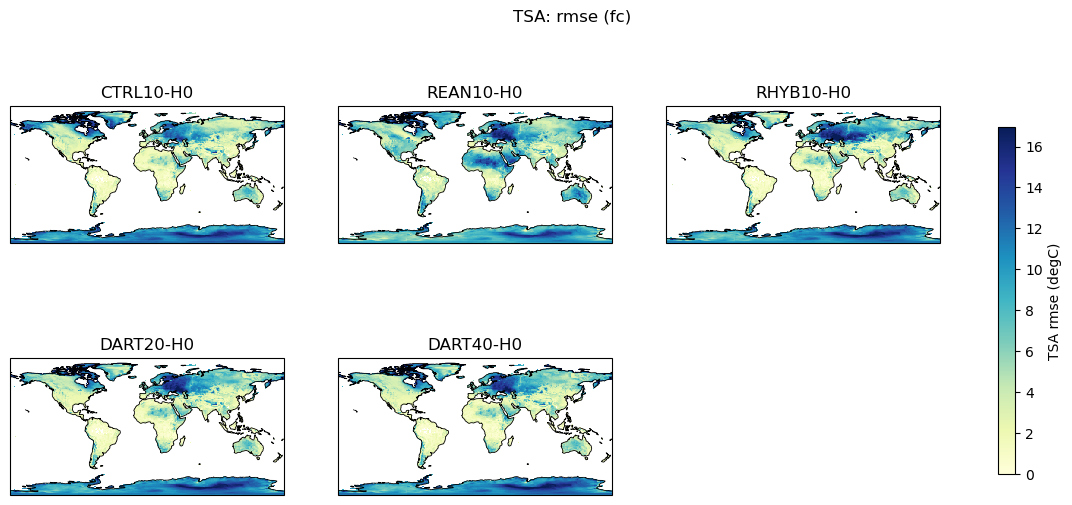

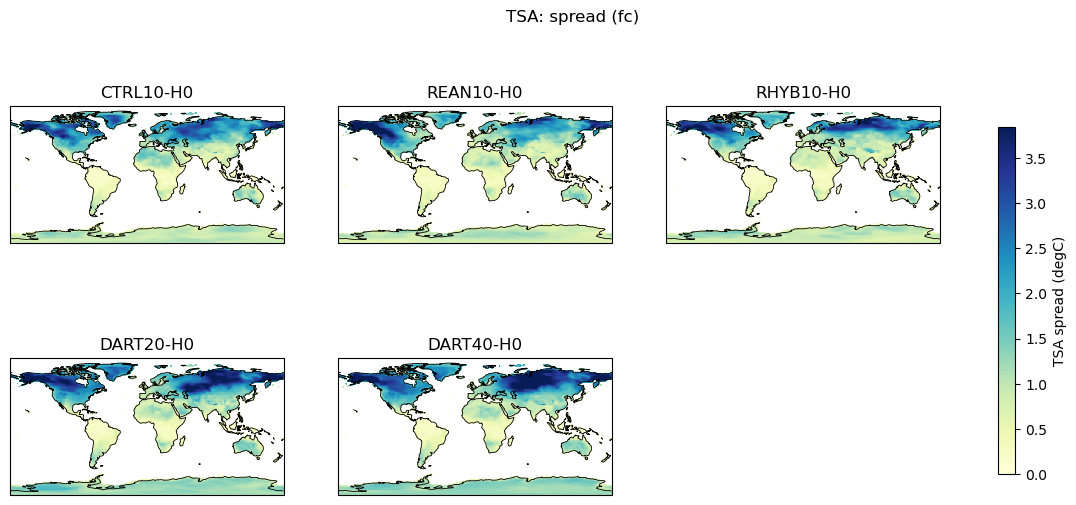

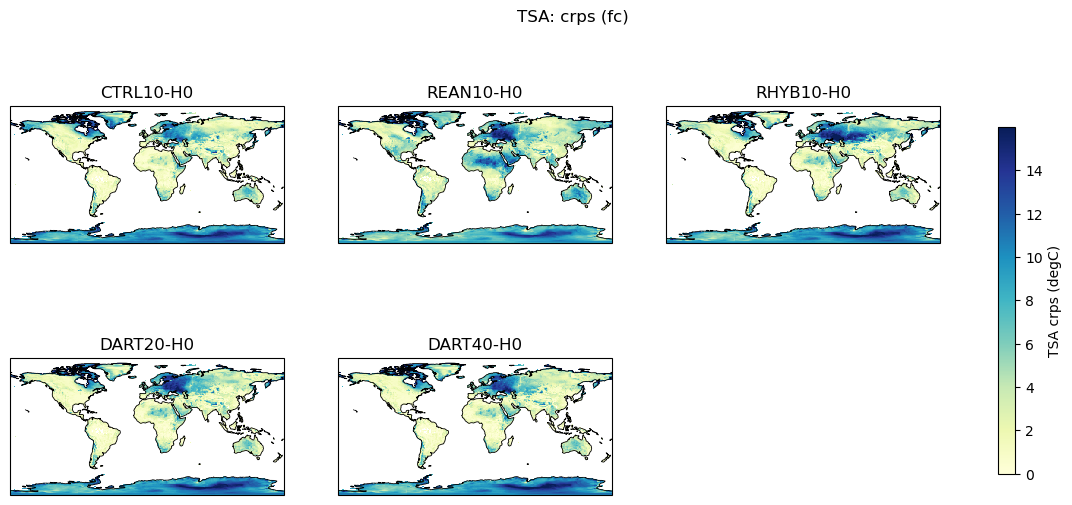

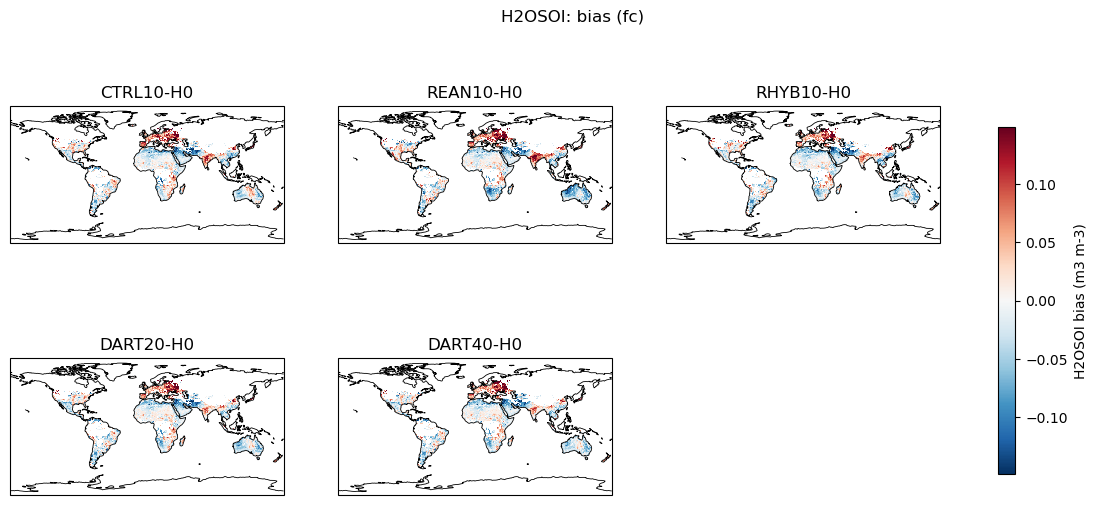

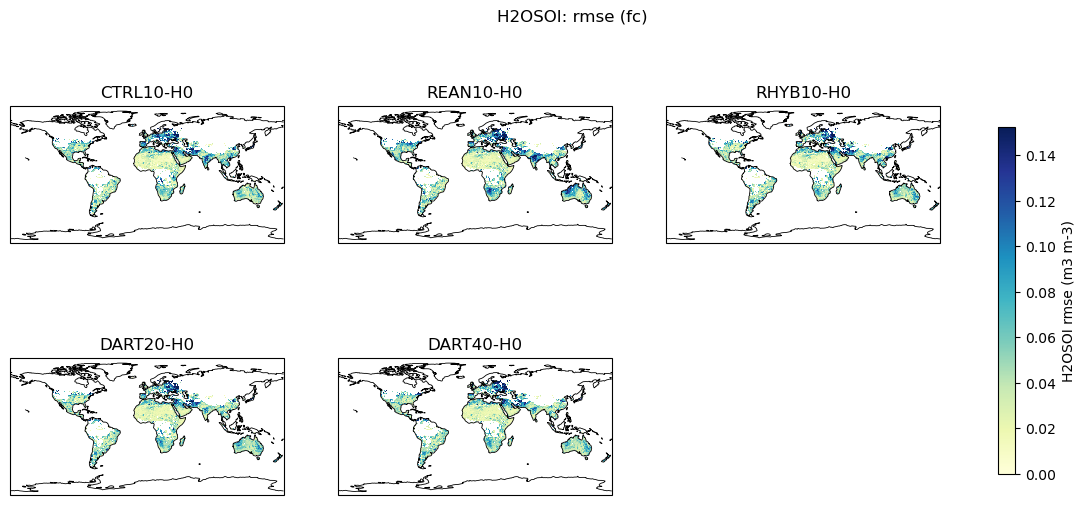

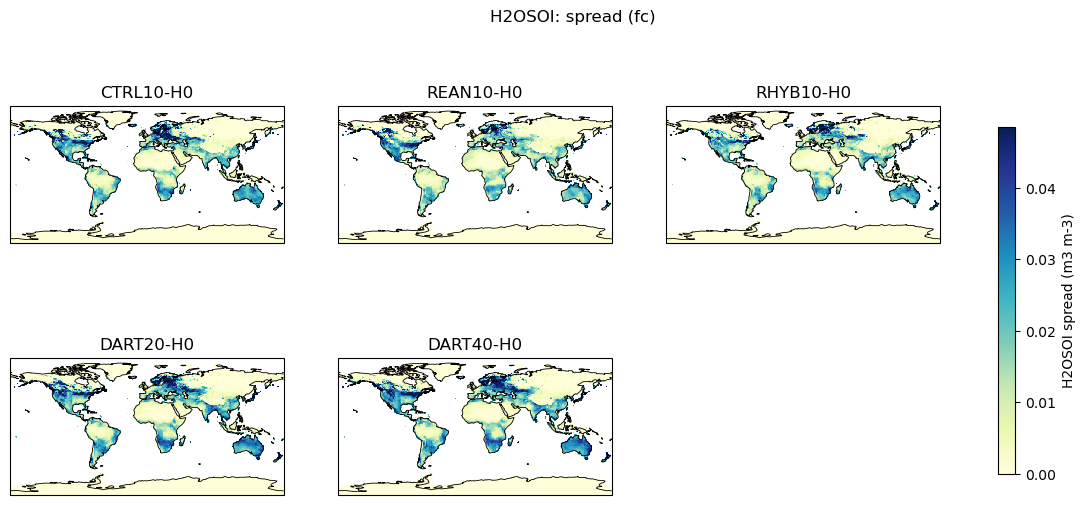

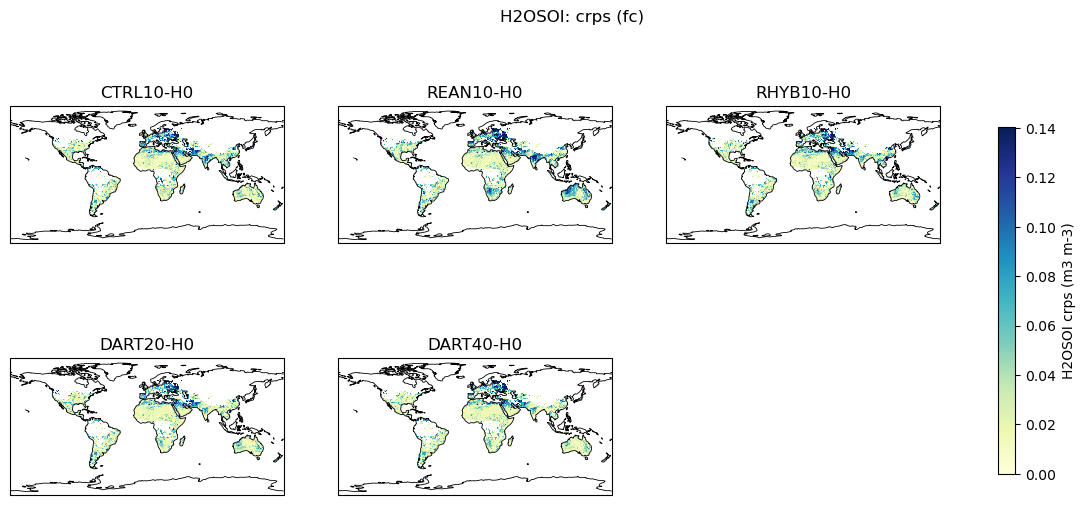

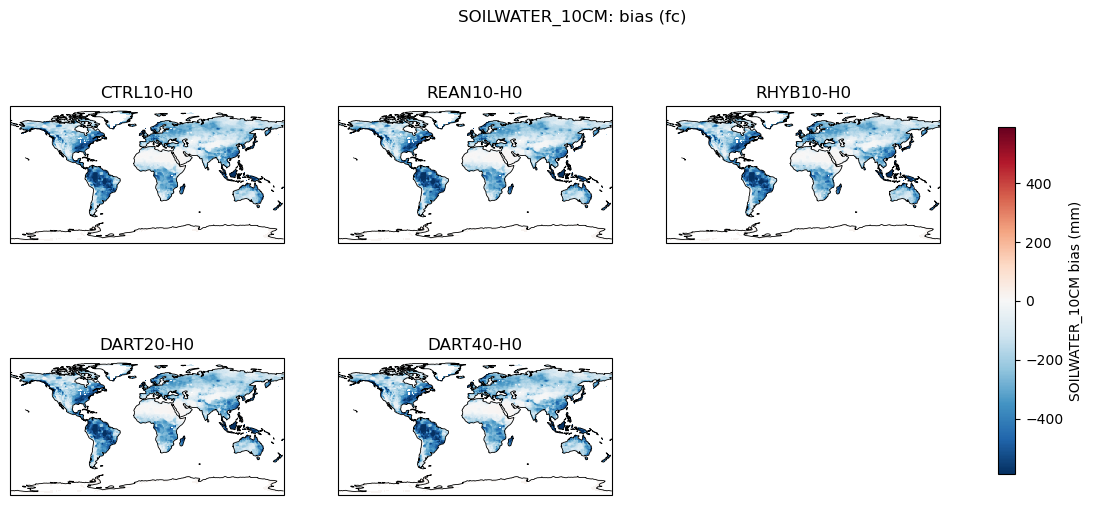

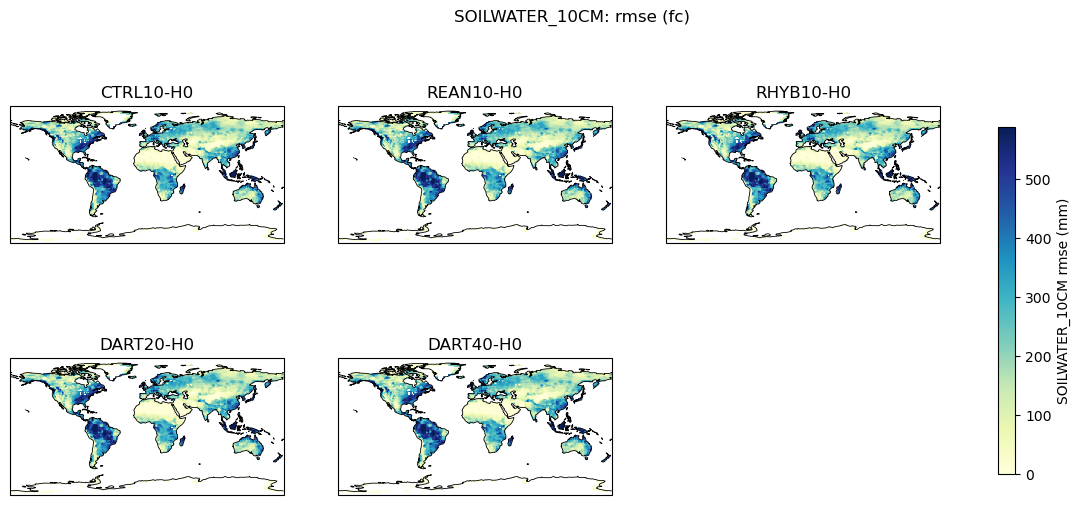

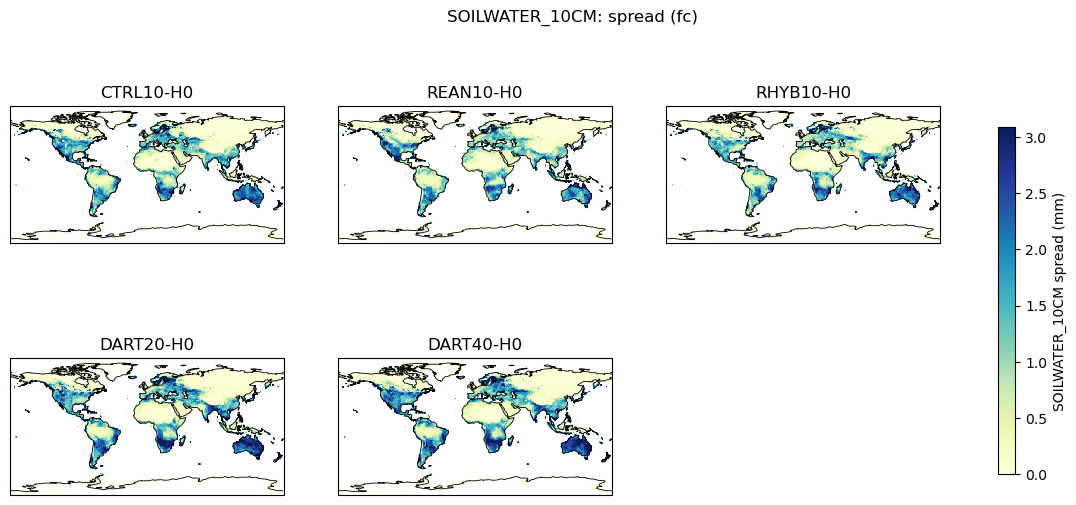

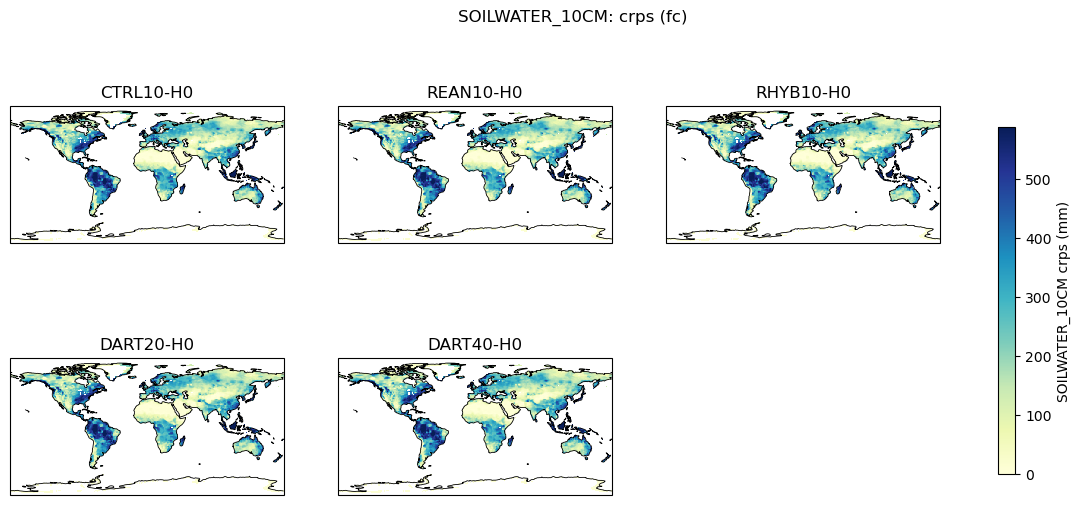

In [5]:
figures = {}
for variable, variable_results in all_results.items():
    for metric in plot_metrics:
        fig = plot_evaluation_maps(
            variable_results, metric, variable,
            label_map={name: registry[name]["label"] for name in experiments},
            title=f"{variable}: {metric} ({run_segment})",
        )
        output = figure_dir / f"{variable}_{metric}_{season}_{run_segment}.png"
        fig.savefig(output, dpi=FIGURE_DPI, bbox_inches="tight")
        figures[(variable, metric)] = fig
        if not show:
            import matplotlib.pyplot as plt
            plt.close(fig)
        print(f"[FIGURE] {output}")

rows = []
for variable, results in all_results.items():
    for experiment, ds in results.items():
        row = {"variable": variable, "experiment": experiment}
        for metric in SCALAR_METRICS:
            if metric in ds:
                row[metric] = float(ds[metric])
        rows.append(row)
summary = pd.DataFrame(rows)
summary
